# Exploratory Data Analysis of the Abalone dataset

The goal of the project is to predict the age of an abalone from physical measurements that are
quick to take, instead of cutting its shell and counting the rings under a microscope.

This notebook explores the dataset to understand:
- the quality of the data (missing values, impossible measurements, outliers)
- the distribution of the target, the number of `Rings` (age in years ≈ rings + 1.5)
- which measurements carry information about the age, and what this implies for modelling

**Data**: download `abalone.csv` from the
[Kaggle page](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset) and put it in the
`data/` folder at the root of the repository. With the Kaggle CLI:

```bash
kaggle datasets download -d rodolfomendes/abalone-dataset -p data --unzip
```

# Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 500)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 72  # keeps the saved notebook small enough to commit

# Data

Each row is one abalone. According to the
[original UCI description](https://archive.ics.uci.edu/dataset/1/abalone), lengths are in mm and
weights in grams, and all continuous values were divided by 200.

| Column | Description |
|---|---|
| `Sex` | M (male), F (female) or I (infant) |
| `Length` | Longest shell measurement |
| `Diameter` | Shell measurement perpendicular to the length |
| `Height` | Height with the meat in the shell |
| `Whole weight` | Weight of the whole abalone |
| `Shucked weight` | Weight of the meat |
| `Viscera weight` | Gut weight, after bleeding |
| `Shell weight` | Weight of the shell, after drying |
| `Rings` | **Target**: number of rings (+1.5 gives the age in years) |

In [2]:
DATA_PATH = Path("../data/abalone.csv")

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(4177, 9)


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


## Data quality

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
df.describe().T

Missing values: 0
Duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


There are no missing values and no duplicated rows. However, the minimum `Height` is 0 and the
maximum (1.13) is far above the third quartile (0.165): let's look at these extreme heights.

In [5]:
df[(df["Height"] == 0) | (df["Height"] > 0.4)]

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.340,0.000,0.428,0.2065,0.0860,0.1150,8
1417,M,0.705,0.565,0.515,2.210,1.1075,0.4865,0.5120,10
2051,F,0.455,0.355,1.130,0.594,0.3320,0.1160,0.1335,8
3996,I,0.315,0.230,0.000,0.134,0.0575,0.0285,0.3505,6


Two infants have a height of 0, which is physically impossible. Two other abalones are 0.515 and
1.13 high, while all the others are at most 0.25: the 1.13 one is only 0.455 long, so this is
much more likely a typo than a giant abalone. We consider these 4 rows (0.1% of the data) as
recording errors and drop them.

In [6]:
df = df[(df["Height"] > 0) & (df["Height"] <= 0.4)]
print(df.shape)

(4173, 9)


The weights should also be consistent: the meat, viscera and shell are parts of the whole
abalone, so together they should not weigh more than it.

In [7]:
parts_weight = df["Shucked weight"] + df["Viscera weight"] + df["Shell weight"]
excess_weight = (parts_weight - df["Whole weight"])[parts_weight > df["Whole weight"]]

print("Parts heavier than the whole abalone:", len(excess_weight))
print("Meat heavier than the whole abalone:", (df["Shucked weight"] > df["Whole weight"]).sum())
excess_weight.describe().round(3)

Parts heavier than the whole abalone: 154
Meat heavier than the whole abalone: 4


count    154.000
mean       0.043
std        0.082
min        0.000
25%        0.004
50%        0.011
75%        0.030
max        0.448
dtype: float64

154 abalones (3.7%) have parts that weigh more than the whole animal, and for 4 of them the meat
alone is heavier. Most of the gaps are tiny (median 0.011, about 2 g) and look like measurement
noise, but we can't tell which of the weights is wrong. We keep these rows.

## Target: number of rings

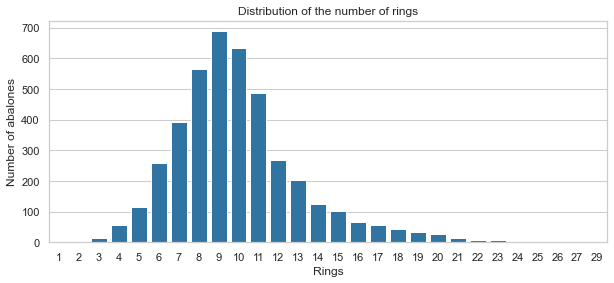

Skewness: 1.11
Abalones with 20 rings or more: 62


count    4173.000000
mean        9.935538
std         3.224861
min         1.000000
25%         8.000000
50%         9.000000
75%        11.000000
max        29.000000
Name: Rings, dtype: float64

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(x=df["Rings"], color="tab:blue", ax=ax)
ax.set(title="Distribution of the number of rings", xlabel="Rings", ylabel="Number of abalones")
plt.show()

print(f"Skewness: {df['Rings'].skew():.2f}")
print("Abalones with 20 rings or more:", (df["Rings"] >= 20).sum())
df["Rings"].describe()

The number of rings ranges from 1 to 29 with a median of 9, and half of the abalones have between
8 and 11 rings. The distribution is right-skewed (skewness of 1.11): only 62 abalones (1.5%) have
20 rings or more. With so few old examples, a model will likely underestimate the age of the
oldest abalones.

As asked, we model the number of rings directly: the age in years is simply rings + 1.5.

## Sex

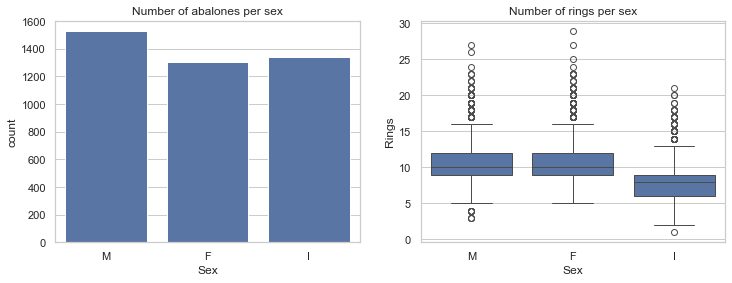

,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
F,1306.0,11.131700,3.104236,5.0,9.0,10.0,12.0,29.0
I,1340.0,7.891791,2.512896,1.0,6.0,8.0,9.0,21.0
M,1527.0,10.705959,3.027287,3.0,9.0,10.0,12.0,27.0


In [9]:
sex_order = ["M", "F", "I"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Sex", order=sex_order, ax=axes[0])
axes[0].set_title("Number of abalones per sex")
sns.boxplot(data=df, x="Sex", y="Rings", order=sex_order, ax=axes[1])
axes[1].set_title("Number of rings per sex")
plt.show()

df.groupby("Sex")["Rings"].describe()

The three categories are balanced. Infants have clearly fewer rings (7.9 on average) than males
(10.7) and females (11.1), which are very similar to each other. The sex is therefore mostly
useful to tell infants from adults. Since it is categorical, it will be one-hot encoded.

## Physical measurements

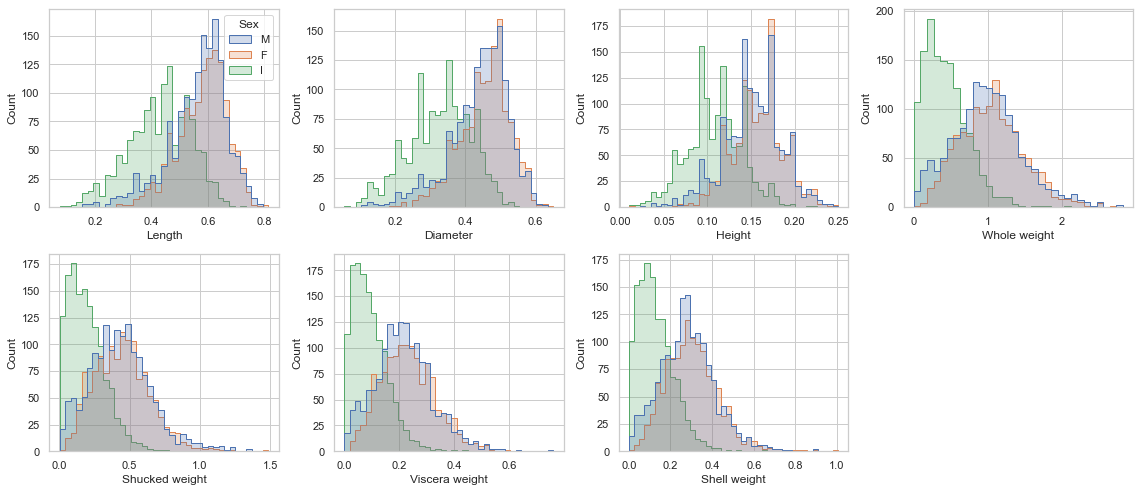

In [10]:
features = df.columns.drop(["Sex", "Rings"])

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, (feature, ax) in enumerate(zip(features, axes.flat)):
    sns.histplot(
        data=df, x=feature, hue="Sex", hue_order=sex_order, element="step", ax=ax, legend=i == 0
    )
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

Infants are smaller and lighter than adults on every measurement, while males and females have
very similar distributions. Length and diameter are slightly left-skewed, and the weights are
right-skewed: weights grow roughly with the cube of the length, so they spread out for the
biggest abalones.

## Correlations

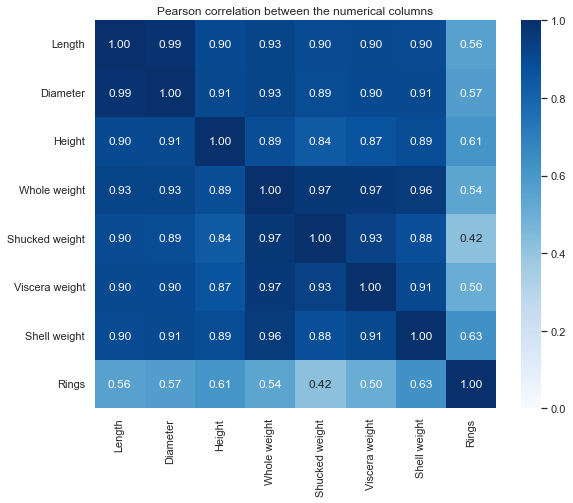

In [11]:
corr = df.drop(columns="Sex").corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Pearson correlation between the numerical columns")
plt.show()

- **Shell weight** is the measurement most correlated with the number of rings (0.63), followed
  by the height (0.61, up from 0.56 before removing the 4 outliers), the diameter and the length.
- All the measurements are **very strongly correlated with each other** (0.84 to 0.99, e.g. 0.99
  between length and diameter): they all describe the size of the abalone. A linear model will
  suffer from multicollinearity: its predictions will be fine, but its coefficients won't be
  interpretable one by one.
- No measurement explains the rings on its own: size only tells part of the story about age.

## Measurements vs number of rings

Since the measurements are so correlated, we only plot four representative ones: the best
predictor (shell weight), one length, the height and one other weight.

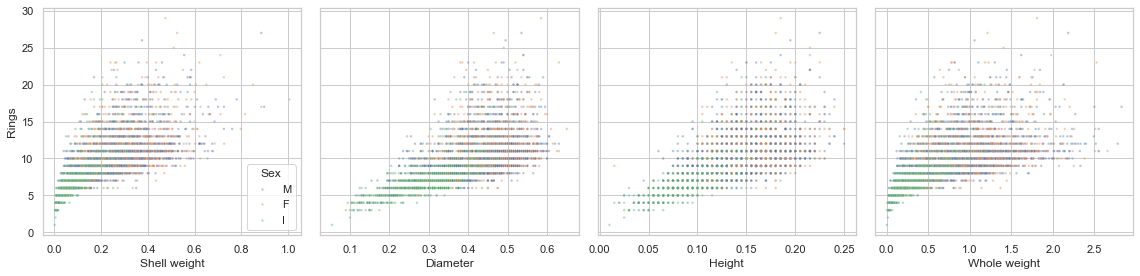

In [12]:
scatter_features = ["Shell weight", "Diameter", "Height", "Whole weight"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for i, (feature, ax) in enumerate(zip(scatter_features, axes)):
    sns.scatterplot(
        data=df,
        x=feature,
        y="Rings",
        hue="Sex",
        hue_order=sex_order,
        s=6,
        alpha=0.4,
        ax=ax,
        legend=i == 0,
    )
plt.tight_layout()
plt.show()

The number of rings increases with each measurement, but the relationship is not linear: it
flattens for the biggest abalones (they grow more slowly as they age). The spread of the rings
also widens with size, which the table below quantifies by splitting the abalones into five
groups of equal size based on their shell weight.

In [13]:
shell_weight_bins = pd.qcut(df["Shell weight"], q=5)
df.groupby(shell_weight_bins, observed=True)["Rings"].agg(["mean", "std"])

,mean,std
Shell weight,,
"(0.0005, 0.109]",6.738038,1.827806
"(0.109, 0.19]",8.955635,2.107939
"(0.19, 0.27]",10.396028,2.671650
"(0.27, 0.352]",11.078818,2.574885
"(0.352, 1.005]",12.531737,3.320944


The mean number of rings goes from 6.7 for the lightest shells to 12.5 for the heaviest, but the
standard deviation almost doubles (from 1.8 to 3.3): two big abalones can have very different
ages. Size alone cannot pin down the age of old abalones, so we should expect an error of a
couple of rings whatever the model.

# Conclusions

- **Data quality**: no missing values or duplicates. The 4 rows with an impossible or extreme
  height must be dropped; the small inconsistencies between weights are kept.
- **Target**: `Rings` ranges from 1 to 29 and is right-skewed, with few old abalones, so errors
  will likely be larger for them.
- **Sex**: to be one-hot encoded. It mostly separates infants (fewer rings) from adults.
- **Measurements**: they all describe the size of the abalone and are strongly correlated with
  each other. Shell weight is the best single predictor (r = 0.63).
- **Relationship with the target**: increasing but non-linear, with a spread that grows with
  the size of the abalone.

For the [modelling notebook](modelling.ipynb): a linear regression is a reasonable first model,
though its coefficients won't be interpretable individually. Tree-based models may capture the
non-linearity better. In any case, we should expect an RMSE of about 2 rings.